# EMBED LNG-EXpansorb MNs — Binary Quality Classification v2

**Task:** Binary classification — Good vs Defective  
**Models:** ResNet50 vs EfficientNetB0 vs VGG16 (transfer learning)  
**Label strategy:** High-confidence trays only:
- **Good class:** Trays where bad=0 AND questionable=0 (every well confirmed good)
- **Defective class:** Trays where defect rate >30% (predominantly defective)

This eliminates label noise caused by proportional approximation across mixed trays.


In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")
OUTPUT_DIR = os.environ.get("OUTPUT_DIR", "../outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)


## Cell 1 — Install & Import

In [1]:
!pip install openpyxl -q

import os
import re
import shutil
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

PyTorch: 2.10.0+cu128
GPU available: True
GPU: Tesla T4
Using device: cuda


## Cell 2 — Copy Dataset to Local SSD

In [2]:
SRC = Path(DATA_DIR)
DST = Path(OUTPUT_DIR + '/data')

if DST.exists():
    print('Dataset already copied. Skipping.')
else:
    print('Copying dataset to local SSD...')
    start = time.time()
    shutil.copytree(SRC, DST)
    print(f'Done in {time.time()-start:.0f}s')

def find_tray_root(base):
    for root, dirs, _ in os.walk(base):
        for d in dirs:
            if re.match(r'^T\d+$', d):
                return Path(root)
    return None

DATASET_ROOT = find_tray_root(DST)
if DATASET_ROOT is None:
    raise FileNotFoundError('Could not find tray folders')
print(f'Dataset root: {DATASET_ROOT}')

Copying dataset to local SSD...
Done in 70s
Dataset root: /kaggle/working/data/datasets/abasssaeedmohammed/embed-lng-expansorb-mns-inspection-2025/EMBED LNG-EXpansorb MNs Inspection 2025


## Cell 3 — Parse Excel & Identify High-Confidence Trays

In [6]:
excel_path = next(Path(DATASET_ROOT).rglob('*.xlsx'), None)
print('Excel:', excel_path)

df_raw = pd.read_excel(excel_path, header=None)
raw    = df_raw.values

tray_counts = {}
current_tray = None

for row in raw:
    row_str = str(row[0]).strip() if pd.notna(row[0]) else ''
    if row_str.startswith('TRAY'):
        m = re.search(r'TRAY\s*(\d+)', row_str)
        if m:
            current_tray = int(m.group(1))
    elif row_str == 'D' and current_tray is not None:
        try:
            g = int(float(row[8]))  if pd.notna(row[8])  else 0
            q = int(float(row[9]))  if pd.notna(row[9])  else 0
            b = int(float(row[10])) if pd.notna(row[10]) else 0
            if g + q + b > 0:
                total = g + q + b
                tray_counts[current_tray] = {
                    'good': g, 'questionable': q, 'bad': b,
                    'total': total,
                    'defect_rate': (q + b) / total
                }
        except (ValueError, TypeError):
            pass

# High-confidence tray selection using rate-based thresholds
GOOD_THRESHOLD     = 0.20  # trays with <20% defective = Good class
DEFECTIVE_THRESHOLD = 0.30  # trays with >30% defective = Defective class

good_trays      = [t for t, c in tray_counts.items()
                   if c['defect_rate'] < GOOD_THRESHOLD]
defective_trays = [t for t, c in tray_counts.items()
                   if c['defect_rate'] > DEFECTIVE_THRESHOLD]
excluded_trays  = [t for t, c in tray_counts.items()
                   if GOOD_THRESHOLD <= c['defect_rate'] <= DEFECTIVE_THRESHOLD]

print(f'Good trays      ({len(good_trays)}): {sorted(good_trays)}')
print(f'Defective trays ({len(defective_trays)}): {sorted(defective_trays)}')
print(f'Excluded trays  ({len(excluded_trays)}): {sorted(excluded_trays)}')
print()
print('--- Good trays ---')
for t in sorted(good_trays):
    c = tray_counts[t]
    print(f'  T{t}: {c["good"]} good, {c["questionable"]+c["bad"]} defective ({c["defect_rate"]*100:.0f}%)')
print('--- Defective trays ---')
for t in sorted(defective_trays):
    c = tray_counts[t]
    print(f'  T{t}: {c["good"]} good, {c["questionable"]+c["bad"]} defective ({c["defect_rate"]*100:.0f}%)')
    print(f'  T{t}: {c["good"]} good, {c["questionable"]+c["bad"]} defective ({c["defect_rate"]*100:.0f}% defective)')

Excel: /kaggle/working/data/datasets/abasssaeedmohammed/embed-lng-expansorb-mns-inspection-2025/EMBED LNG-EXpansorb MNs Inspection 2025/EMBED 3.0 LC MNs 2025 04.xlsx
Good trays      (13): [8, 17, 23, 24, 28, 30, 32, 33, 34, 36, 37, 38, 39]
Defective trays (15): [1, 3, 4, 5, 6, 13, 14, 16, 20, 21, 25, 26, 27, 35, 41]
Excluded trays  (13): [2, 7, 9, 10, 11, 12, 15, 18, 19, 22, 29, 31, 40]

--- Good trays ---
  T8: 20 good, 4 defective (17%)
  T17: 23 good, 1 defective (4%)
  T23: 20 good, 4 defective (17%)
  T24: 20 good, 4 defective (17%)
  T28: 20 good, 4 defective (17%)
  T30: 20 good, 4 defective (17%)
  T32: 23 good, 1 defective (4%)
  T33: 20 good, 4 defective (17%)
  T34: 23 good, 1 defective (4%)
  T36: 20 good, 4 defective (17%)
  T37: 20 good, 4 defective (17%)
  T38: 20 good, 4 defective (17%)
  T39: 21 good, 3 defective (12%)
--- Defective trays ---
  T1: 16 good, 8 defective (33%)
  T1: 16 good, 8 defective (33% defective)
  T3: 13 good, 11 defective (46%)
  T3: 13 good, 11 

## Cell 4 — Build Clean Image-Label DataFrame

In [7]:
LABEL_MAP  = {'good': 0, 'defective': 1}
CLASS_NAMES = ['Good', 'Defective']

def get_tray_images(tray_num):
    tray_dir = DATASET_ROOT / f'T{tray_num}'
    if not tray_dir.exists():
        return []
    return sorted(
        list(tray_dir.rglob('*.jpg'))  +
        list(tray_dir.rglob('*.JPG'))  +
        list(tray_dir.rglob('*.jpeg')) +
        list(tray_dir.rglob('*.png'))
    )

records = []

# All images from good trays = Good label
for tray_num in good_trays:
    for img_path in get_tray_images(tray_num):
        records.append({
            'path': str(img_path), 'tray': tray_num,
            'label': 'good', 'label_int': 0
        })

# All images from defective trays = Defective label
for tray_num in defective_trays:
    for img_path in get_tray_images(tray_num):
        records.append({
            'path': str(img_path), 'tray': tray_num,
            'label': 'defective', 'label_int': 1
        })

df = pd.DataFrame(records)
print(f'Total images: {len(df)}')
print('Label distribution:')
vc = df['label'].value_counts()
print(vc)
print(f'\nGood trays: {sorted(good_trays)}')
print(f'Defective trays: {sorted(defective_trays)}')
print(f'\nClass ratio: {vc["good"]}:{vc["defective"]} ({vc["good"]/len(df)*100:.1f}% vs {vc["defective"]/len(df)*100:.1f}%)')

Total images: 4012
Label distribution:
label
defective    2140
good         1872
Name: count, dtype: int64

Good trays: [8, 17, 23, 24, 28, 30, 32, 33, 34, 36, 37, 38, 39]
Defective trays: [1, 3, 4, 5, 6, 13, 14, 16, 20, 21, 25, 26, 27, 35, 41]

Class ratio: 1872:2140 (46.7% vs 53.3%)


## Cell 5 — Exploratory Data Analysis

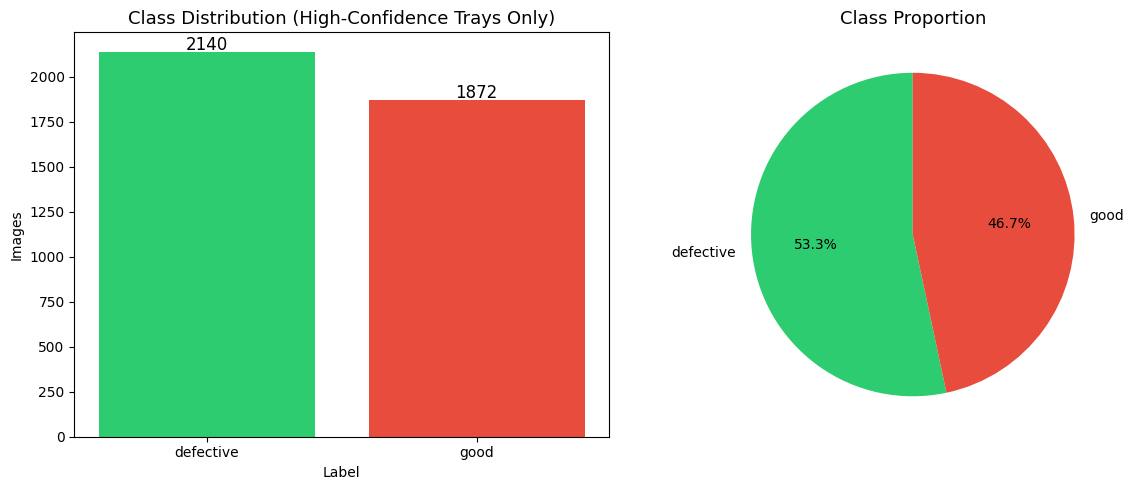

In [8]:
colors = ['#2ecc71', '#e74c3c']
vc     = df['label'].value_counts()

# Class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(vc.index, vc.values, color=colors)
axes[0].set_title('Class Distribution (High-Confidence Trays Only)', fontsize=13)
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Images')
for i, (k, v) in enumerate(vc.items()):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=12)
axes[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Class Proportion', fontsize=13)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

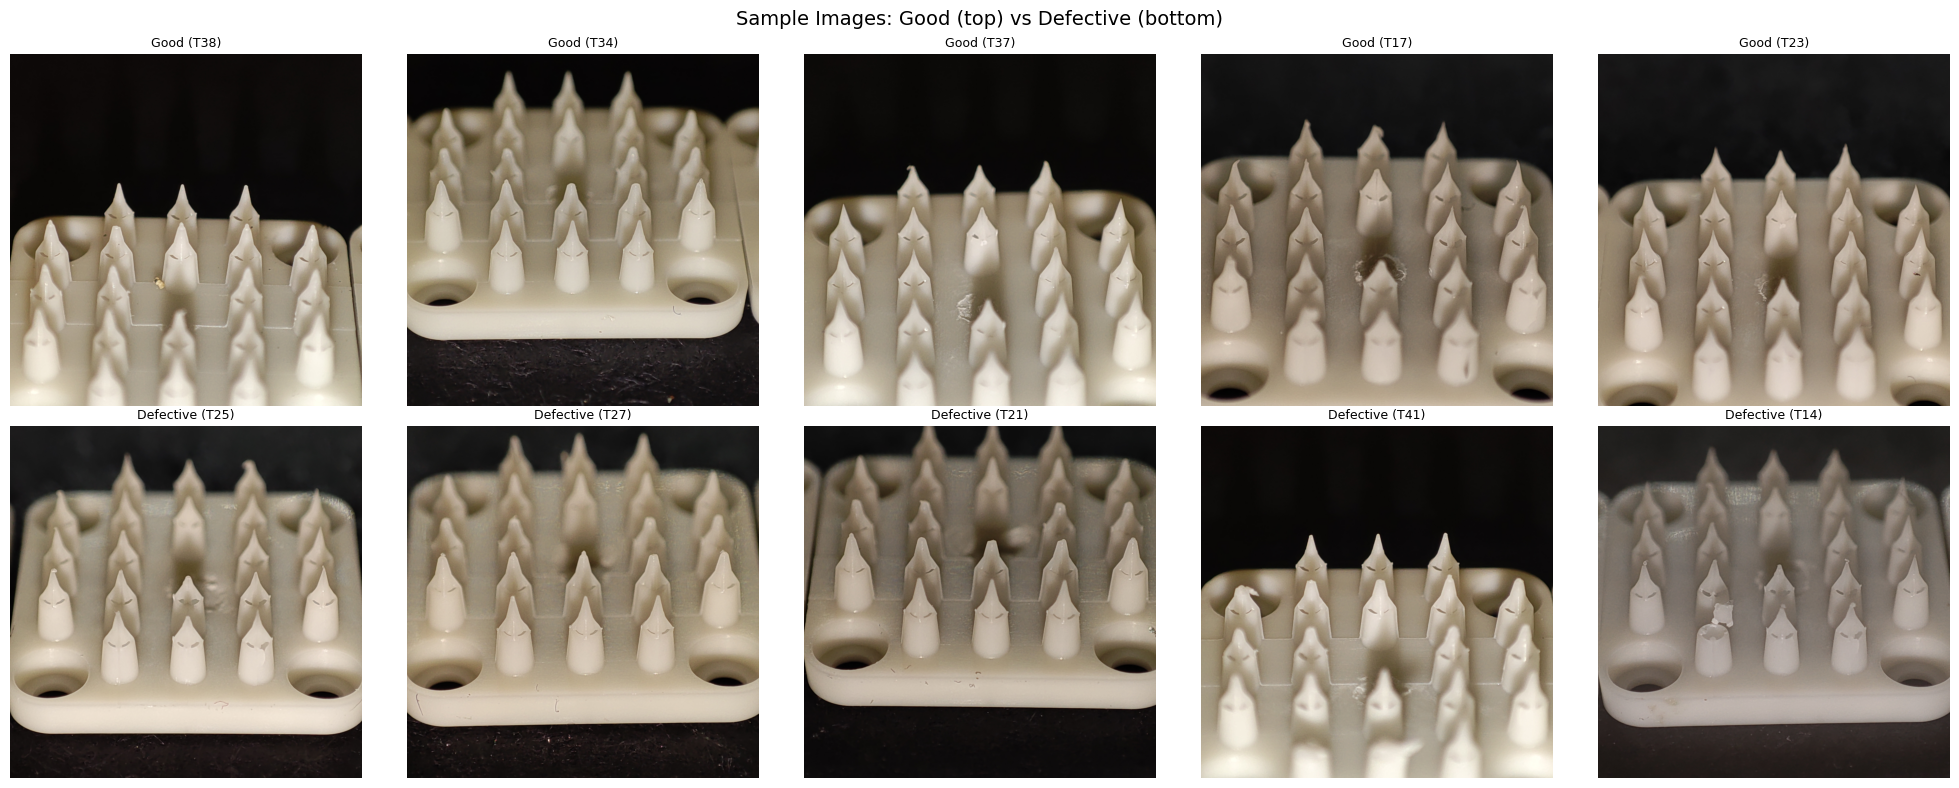

In [9]:
# Sample images
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('Sample Images: Good (top) vs Defective (bottom)', fontsize=14)
for row_idx, label in enumerate(['good', 'defective']):
    samples = df[df['label'] == label].sample(5, random_state=42)
    for col_idx, (_, s) in enumerate(samples.iterrows()):
        img = Image.open(s['path']).convert('RGB')
        axes[row_idx][col_idx].imshow(img)
        axes[row_idx][col_idx].set_title(f"{label.capitalize()} (T{s['tray']})", fontsize=9)
        axes[row_idx][col_idx].axis('off')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150)
plt.show()

--- Image Statistics ---
Resolution: 1944x1944 to 1944x1944
Mean brightness: 93.5 ± 17.7
  Good: mean=98.5, std=15.6, n=100
  Defective: mean=88.5, std=18.3, n=100


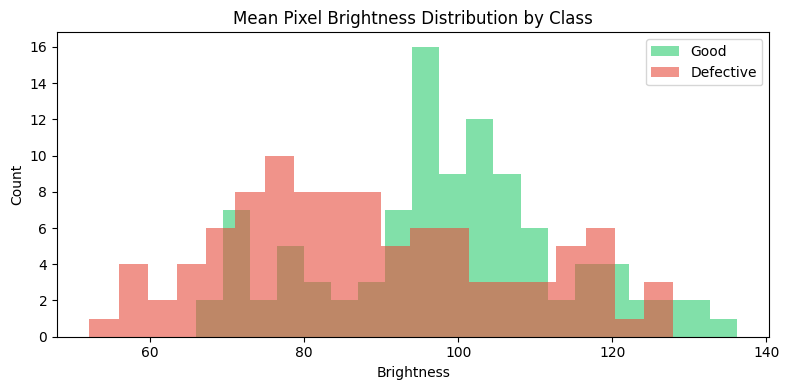

In [10]:
# Image statistics
sample_df = df.sample(min(200, len(df)), random_state=42).copy()
brightnesses = []
sizes = []
for _, row in sample_df.iterrows():
    try:
        img = Image.open(row['path']).convert('RGB')
        arr = np.array(img)
        sizes.append(img.size)
        brightnesses.append(arr.mean())
    except:
        brightnesses.append(None)

sample_df['brightness'] = brightnesses
sample_df = sample_df.dropna(subset=['brightness'])
widths  = [s[0] for s in sizes]
heights = [s[1] for s in sizes]

print('--- Image Statistics ---')
print(f'Resolution: {min(widths)}x{min(heights)} to {max(widths)}x{max(heights)}')
print(f'Mean brightness: {sample_df["brightness"].mean():.1f} ± {sample_df["brightness"].std():.1f}')
for label, color in zip(['good', 'defective'], colors):
    b = sample_df[sample_df['label'] == label]['brightness']
    print(f'  {label.capitalize()}: mean={b.mean():.1f}, std={b.std():.1f}, n={len(b)}')

fig, ax = plt.subplots(figsize=(8, 4))
for label, color in zip(['good', 'defective'], colors):
    subset = sample_df[sample_df['label'] == label]['brightness']
    ax.hist(subset, bins=20, alpha=0.6, label=label.capitalize(), color=color)
ax.set_title('Mean Pixel Brightness Distribution by Class')
ax.set_xlabel('Brightness')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.savefig('brightness_distribution.png', dpi=150)
plt.show()

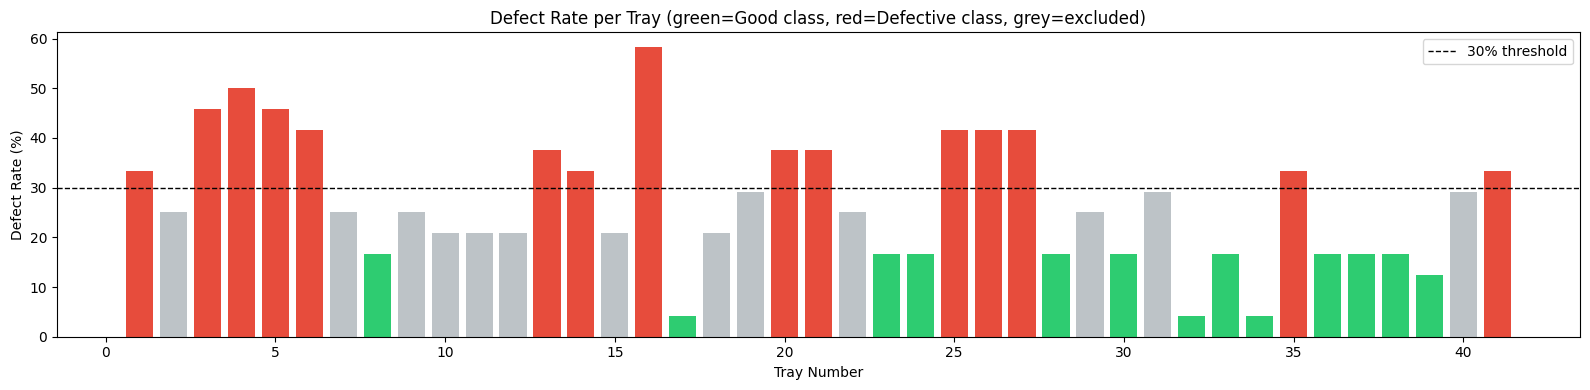

In [11]:
# Tray-level defect rate chart
tray_info = []
for t, c in sorted(tray_counts.items()):
    label = 'good' if t in good_trays else ('defective' if t in defective_trays else 'excluded')
    tray_info.append({'tray': t, 'defect_rate': c['defect_rate']*100, 'used_as': label})
tray_df = pd.DataFrame(tray_info)

color_map = {'good': '#2ecc71', 'defective': '#e74c3c', 'excluded': '#bdc3c7'}
bar_colors = [color_map[l] for l in tray_df['used_as']]

fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(tray_df['tray'], tray_df['defect_rate'], color=bar_colors)
ax.axhline(y=30, color='black', linestyle='--', linewidth=1, label='30% threshold')
ax.set_title('Defect Rate per Tray (green=Good class, red=Defective class, grey=excluded)')
ax.set_xlabel('Tray Number')
ax.set_ylabel('Defect Rate (%)')
ax.legend()
plt.tight_layout()
plt.savefig('tray_defect_rates.png', dpi=150)
plt.show()

## Cell 6 — Train / Validation / Test Split

In [12]:
# Split at tray level — stratified by label
tray_labels = df[['tray', 'label']].drop_duplicates().reset_index(drop=True)

train_trays_df, temp_df = train_test_split(
    tray_labels, test_size=0.3, stratify=tray_labels['label'], random_state=SEED
)
val_trays_df, test_trays_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)

train_trays = set(train_trays_df['tray'])
val_trays   = set(val_trays_df['tray'])
test_trays  = set(test_trays_df['tray'])

train_df = df[df['tray'].isin(train_trays)].reset_index(drop=True)
val_df   = df[df['tray'].isin(val_trays)].reset_index(drop=True)
test_df  = df[df['tray'].isin(test_trays)].reset_index(drop=True)

print(f'Train: {len(train_df)} images | {len(train_trays)} trays: {sorted(train_trays)}')
print(f'Val:   {len(val_df)} images  | {len(val_trays)} trays: {sorted(val_trays)}')
print(f'Test:  {len(test_df)} images  | {len(test_trays)} trays: {sorted(test_trays)}')
print(f'Total: {len(train_df)+len(val_df)+len(test_df)} (must equal {len(df)})')
print()
print('Train:', train_df['label'].value_counts().to_dict())
print('Val:  ', val_df['label'].value_counts().to_dict())
print('Test: ', test_df['label'].value_counts().to_dict())

Train: 2718 images | 19 trays: [1, 3, 4, 6, 8, 13, 17, 20, 21, 24, 26, 28, 32, 34, 35, 36, 37, 38, 41]
Val:   576 images  | 4 trays: [23, 25, 27, 30]
Test:  718 images  | 5 trays: [5, 14, 16, 33, 39]
Total: 4012 (must equal 4012)

Train: {'defective': 1422, 'good': 1296}
Val:   {'good': 288, 'defective': 288}
Test:  {'defective': 430, 'good': 288}


## Cell 7 — Dataset & Augmentation

In [13]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class MicroneedleDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['path']).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, row['label_int']

BATCH_SIZE = 32

train_loader = DataLoader(MicroneedleDataset(train_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(MicroneedleDataset(val_df,   val_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(MicroneedleDataset(test_df,  val_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

Train batches: 85 | Val: 18 | Test: 23


## Cell 8 — Model Builder & Training Functions

In [14]:
NUM_CLASSES = 2
EPOCHS      = 20
LR          = 1e-4

def build_model(model_name):
    if model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.layer4.parameters():
            param.requires_grad = True
        model.fc = nn.Sequential(
            nn.Linear(model.fc.in_features, 256), nn.ReLU(),
            nn.Dropout(0.4), nn.Linear(256, NUM_CLASSES)
        )

    elif model_name == 'efficientnet':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-3:].parameters():
            param.requires_grad = True
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(in_features, 256),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, NUM_CLASSES)
        )

    elif model_name == 'vgg16':
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-6:].parameters():
            param.requires_grad = True
        model.classifier[6] = nn.Sequential(
            nn.Linear(4096, 256), nn.ReLU(),
            nn.Dropout(0.4), nn.Linear(256, NUM_CLASSES)
        )

    return model.to(DEVICE)


def get_class_weights():
    counts = train_df['label'].value_counts()
    total  = len(train_df)
    return torch.tensor([
        total / (NUM_CLASSES * counts.get('good',      1)),
        total / (NUM_CLASSES * counts.get('defective', 1))
    ], dtype=torch.float).to(DEVICE)


def train_model(model, model_name, train_loader, val_loader, epochs=EPOCHS):
    criterion = nn.CrossEntropyLoss(weight=get_class_weights())
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()), lr=LR
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0

    for epoch in range(epochs):
        model.train()
        run_loss, correct, total_n = 0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            out  = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * imgs.size(0)
            _, preds  = out.max(1)
            correct  += (preds == labels).sum().item()
            total_n  += imgs.size(0)
        train_loss = run_loss / total_n
        train_acc  = correct  / total_n

        model.eval()
        v_loss, v_correct, v_total = 0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                out    = model(imgs)
                v_loss += criterion(out, labels).item() * imgs.size(0)
                _, preds = out.max(1)
                v_correct += (preds == labels).sum().item()
                v_total   += imgs.size(0)
        val_loss = v_loss    / v_total
        val_acc  = v_correct / v_total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), f'best_{model_name}.pth')

        scheduler.step()
        print(f'[{model_name}] Epoch {epoch+1:02d}/{epochs} | '
              f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

    print(f'\nBest Val Accuracy [{model_name}]: {best_val_acc:.4f}')
    return history


def evaluate_model(model, model_name, loader):
    model.load_state_dict(torch.load(f'best_{model_name}.pth'))
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            out  = model(imgs.to(DEVICE))
            prob = torch.softmax(out, dim=1)[:, 1]
            _, preds = out.max(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(prob.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

print('All functions defined. Ready to train.')

All functions defined. Ready to train.


## Cell 9 — Train ResNet50

In [15]:
print('=== Training ResNet50 ===')
resnet_model   = build_model('resnet50')
resnet_history = train_model(resnet_model, 'resnet50', train_loader, val_loader)

=== Training ResNet50 ===
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 209MB/s]


[resnet50] Epoch 01/20 | Train Loss: 0.5832 Acc: 0.6814 | Val Loss: 0.9348 Acc: 0.4479
[resnet50] Epoch 02/20 | Train Loss: 0.5189 Acc: 0.7322 | Val Loss: 0.7037 Acc: 0.5642
[resnet50] Epoch 03/20 | Train Loss: 0.4691 Acc: 0.7697 | Val Loss: 0.6998 Acc: 0.4965
[resnet50] Epoch 04/20 | Train Loss: 0.4553 Acc: 0.7667 | Val Loss: 0.9063 Acc: 0.4826
[resnet50] Epoch 05/20 | Train Loss: 0.4105 Acc: 0.8028 | Val Loss: 0.9074 Acc: 0.4427
[resnet50] Epoch 06/20 | Train Loss: 0.4020 Acc: 0.8116 | Val Loss: 0.8510 Acc: 0.5017
[resnet50] Epoch 07/20 | Train Loss: 0.3622 Acc: 0.8319 | Val Loss: 0.9895 Acc: 0.5712
[resnet50] Epoch 08/20 | Train Loss: 0.3549 Acc: 0.8330 | Val Loss: 0.8615 Acc: 0.5521
[resnet50] Epoch 09/20 | Train Loss: 0.3326 Acc: 0.8429 | Val Loss: 0.7773 Acc: 0.5729
[resnet50] Epoch 10/20 | Train Loss: 0.3183 Acc: 0.8477 | Val Loss: 1.0608 Acc: 0.5399
[resnet50] Epoch 11/20 | Train Loss: 0.2970 Acc: 0.8547 | Val Loss: 0.5748 Acc: 0.6823
[resnet50] Epoch 12/20 | Train Loss: 0.2888

## Cell 10 — Train EfficientNetB0

In [16]:
print('=== Training EfficientNetB0 ===')
effnet_model   = build_model('efficientnet')
effnet_history = train_model(effnet_model, 'efficientnet', train_loader, val_loader)

=== Training EfficientNetB0 ===
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 210MB/s]


[efficientnet] Epoch 01/20 | Train Loss: 0.6297 Acc: 0.6575 | Val Loss: 0.7704 Acc: 0.4219
[efficientnet] Epoch 02/20 | Train Loss: 0.5392 Acc: 0.7145 | Val Loss: 0.8501 Acc: 0.3559
[efficientnet] Epoch 03/20 | Train Loss: 0.5056 Acc: 0.7509 | Val Loss: 0.7785 Acc: 0.4757
[efficientnet] Epoch 04/20 | Train Loss: 0.4786 Acc: 0.7605 | Val Loss: 0.8456 Acc: 0.4948
[efficientnet] Epoch 05/20 | Train Loss: 0.4551 Acc: 0.7848 | Val Loss: 0.8077 Acc: 0.4983
[efficientnet] Epoch 06/20 | Train Loss: 0.4286 Acc: 0.7947 | Val Loss: 0.7956 Acc: 0.5833
[efficientnet] Epoch 07/20 | Train Loss: 0.4265 Acc: 0.7932 | Val Loss: 0.7524 Acc: 0.6024
[efficientnet] Epoch 08/20 | Train Loss: 0.4042 Acc: 0.7965 | Val Loss: 0.7441 Acc: 0.5885
[efficientnet] Epoch 09/20 | Train Loss: 0.3959 Acc: 0.8102 | Val Loss: 1.0099 Acc: 0.5174
[efficientnet] Epoch 10/20 | Train Loss: 0.3798 Acc: 0.8131 | Val Loss: 0.6671 Acc: 0.6042
[efficientnet] Epoch 11/20 | Train Loss: 0.3541 Acc: 0.8289 | Val Loss: 0.8756 Acc: 0.5694

## Cell 11 — Train VGG16

In [17]:
print('=== Training VGG16 ===')
vgg_model   = build_model('vgg16')
vgg_history = train_model(vgg_model, 'vgg16', train_loader, val_loader)

=== Training VGG16 ===
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 230MB/s] 


[vgg16] Epoch 01/20 | Train Loss: 0.6473 Acc: 0.6096 | Val Loss: 0.8016 Acc: 0.4306
[vgg16] Epoch 02/20 | Train Loss: 0.5806 Acc: 0.6829 | Val Loss: 0.7574 Acc: 0.3837
[vgg16] Epoch 03/20 | Train Loss: 0.5409 Acc: 0.7042 | Val Loss: 0.7784 Acc: 0.4688
[vgg16] Epoch 04/20 | Train Loss: 0.5314 Acc: 0.7163 | Val Loss: 0.8118 Acc: 0.4080
[vgg16] Epoch 05/20 | Train Loss: 0.5111 Acc: 0.7322 | Val Loss: 0.9142 Acc: 0.3733
[vgg16] Epoch 06/20 | Train Loss: 0.5185 Acc: 0.7325 | Val Loss: 0.7998 Acc: 0.4705
[vgg16] Epoch 07/20 | Train Loss: 0.4912 Acc: 0.7494 | Val Loss: 0.9635 Acc: 0.3889
[vgg16] Epoch 08/20 | Train Loss: 0.4752 Acc: 0.7590 | Val Loss: 0.8762 Acc: 0.4844
[vgg16] Epoch 09/20 | Train Loss: 0.4676 Acc: 0.7660 | Val Loss: 0.9708 Acc: 0.4201
[vgg16] Epoch 10/20 | Train Loss: 0.4536 Acc: 0.7660 | Val Loss: 0.8982 Acc: 0.5000
[vgg16] Epoch 11/20 | Train Loss: 0.4500 Acc: 0.7712 | Val Loss: 1.0178 Acc: 0.3924
[vgg16] Epoch 12/20 | Train Loss: 0.4368 Acc: 0.7837 | Val Loss: 0.8729 Acc:

## Cell 12 — Results & Comparison

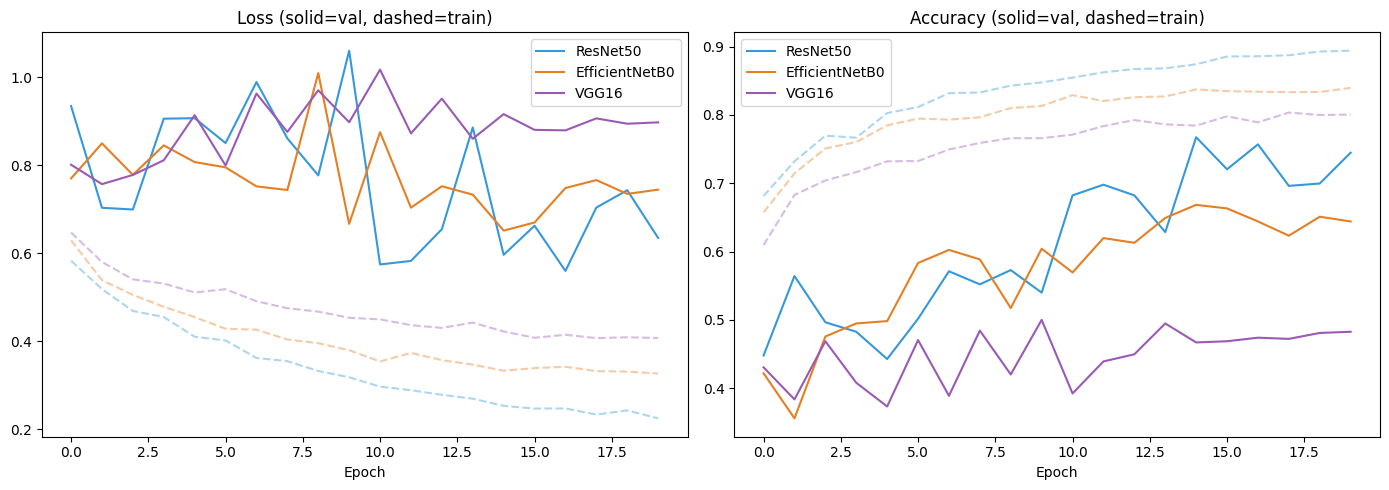

In [18]:
display_names = {'resnet50': 'ResNet50', 'efficientnet': 'EfficientNetB0', 'vgg16': 'VGG16'}
model_lookup  = {'resnet50': resnet_model, 'efficientnet': effnet_model, 'vgg16': vgg_model}
line_colors   = ['#3498db', '#e67e22', '#9b59b6']

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for hist, name, c in zip(
    [resnet_history, effnet_history, vgg_history],
    list(display_names.values()), line_colors
):
    axes[0].plot(hist['train_loss'], '--', color=c, alpha=0.4)
    axes[0].plot(hist['val_loss'],   '-',  color=c, label=name)
    axes[1].plot(hist['train_acc'],  '--', color=c, alpha=0.4)
    axes[1].plot(hist['val_acc'],    '-',  color=c, label=name)
axes[0].set_title('Loss (solid=val, dashed=train)'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].set_title('Accuracy (solid=val, dashed=train)'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

In [19]:
# Evaluate all models
results = {}
for name, model in model_lookup.items():
    preds, labels, probs = evaluate_model(model, name, test_loader)
    report = classification_report(labels, preds, target_names=CLASS_NAMES, output_dict=True)
    fpr, tpr, _ = roc_curve(labels, probs)
    roc_auc = auc(fpr, tpr)
    results[name] = {'report': report, 'preds': preds,
                     'labels': labels, 'probs': probs,
                     'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}
    print(f'\n=== {display_names[name]} ===')
    print(classification_report(labels, preds, target_names=CLASS_NAMES))
    print(f'ROC-AUC: {roc_auc:.4f}')


=== ResNet50 ===
              precision    recall  f1-score   support

        Good       0.62      0.80      0.70       288
   Defective       0.83      0.67      0.74       430

    accuracy                           0.72       718
   macro avg       0.73      0.73      0.72       718
weighted avg       0.75      0.72      0.72       718

ROC-AUC: 0.7767

=== EfficientNetB0 ===
              precision    recall  f1-score   support

        Good       0.70      1.00      0.82       288
   Defective       1.00      0.71      0.83       430

    accuracy                           0.82       718
   macro avg       0.85      0.85      0.82       718
weighted avg       0.88      0.82      0.83       718

ROC-AUC: 0.8416

=== VGG16 ===
              precision    recall  f1-score   support

        Good       0.52      0.85      0.64       288
   Defective       0.82      0.47      0.60       430

    accuracy                           0.62       718
   macro avg       0.67      0.66      

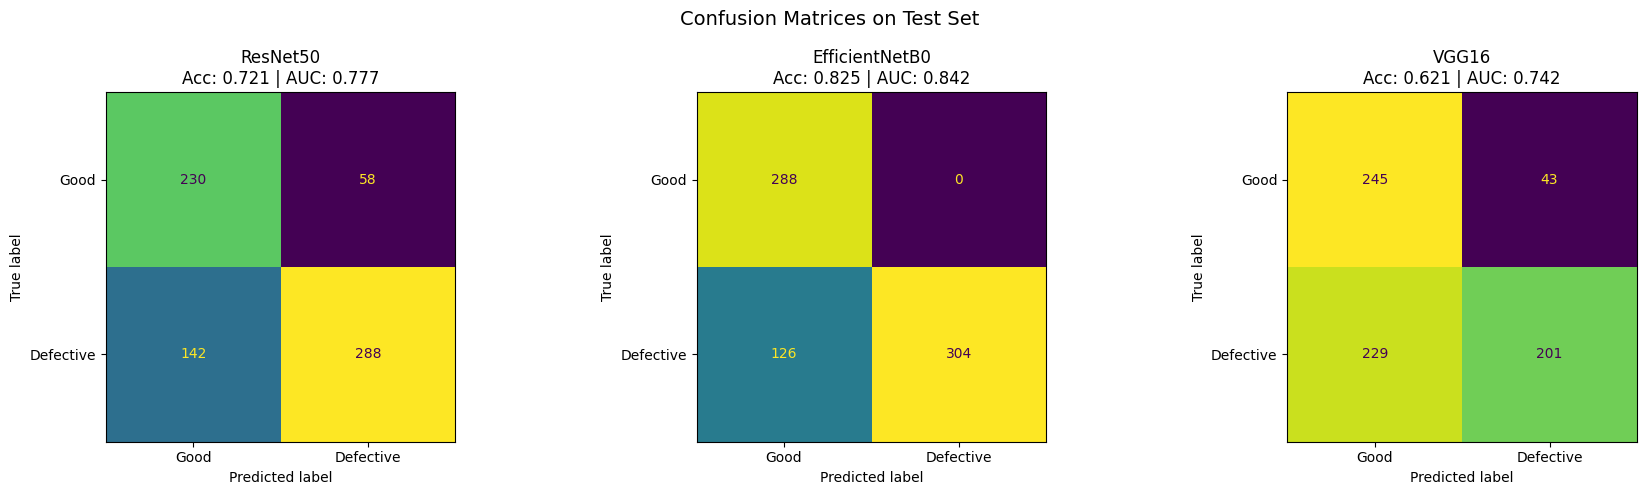

In [20]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices on Test Set', fontsize=14)
for idx, (name, data) in enumerate(results.items()):
    cm = confusion_matrix(data['labels'], data['preds'])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=axes[idx], colorbar=False)
    r = data['report']
    axes[idx].set_title(
        f"{display_names[name]}\nAcc: {r['accuracy']:.3f} | AUC: {data['auc']:.3f}"
    )
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

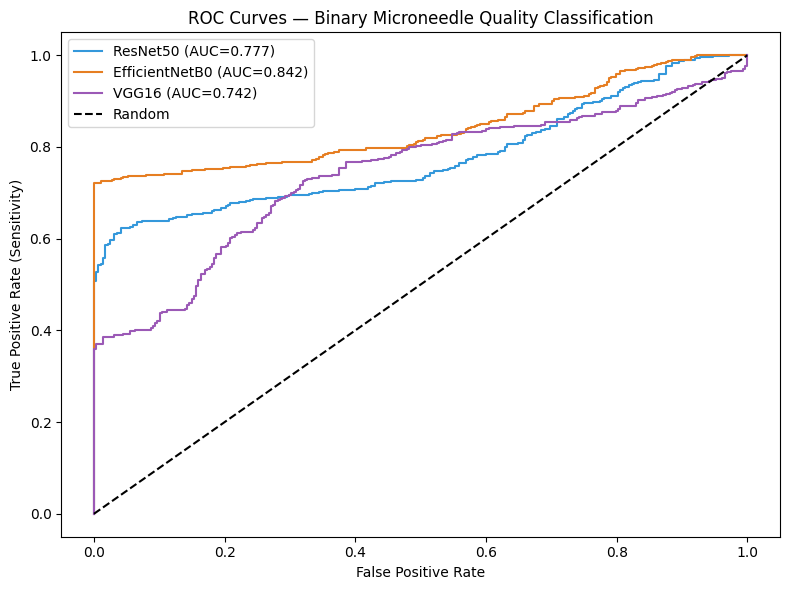

In [21]:
# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
for (name, data), color in zip(results.items(), line_colors):
    ax.plot(data['fpr'], data['tpr'], color=color,
            label=f"{display_names[name]} (AUC={data['auc']:.3f})")
ax.plot([0,1],[0,1],'k--', label='Random')
ax.set_title('ROC Curves — Binary Microneedle Quality Classification')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.legend()
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150)
plt.show()


=== FINAL MODEL COMPARISON ===
         Model  Accuracy  ROC-AUC  Good F1  Defective F1  Macro F1  Defective Recall  Defective Precision
      ResNet50    0.7214   0.7767   0.6970        0.7423    0.7196            0.6698               0.8324
EfficientNetB0    0.8245   0.8416   0.8205        0.8283    0.8244            0.7070               1.0000
         VGG16    0.6212   0.7422   0.6430        0.5964    0.6197            0.4674               0.8238


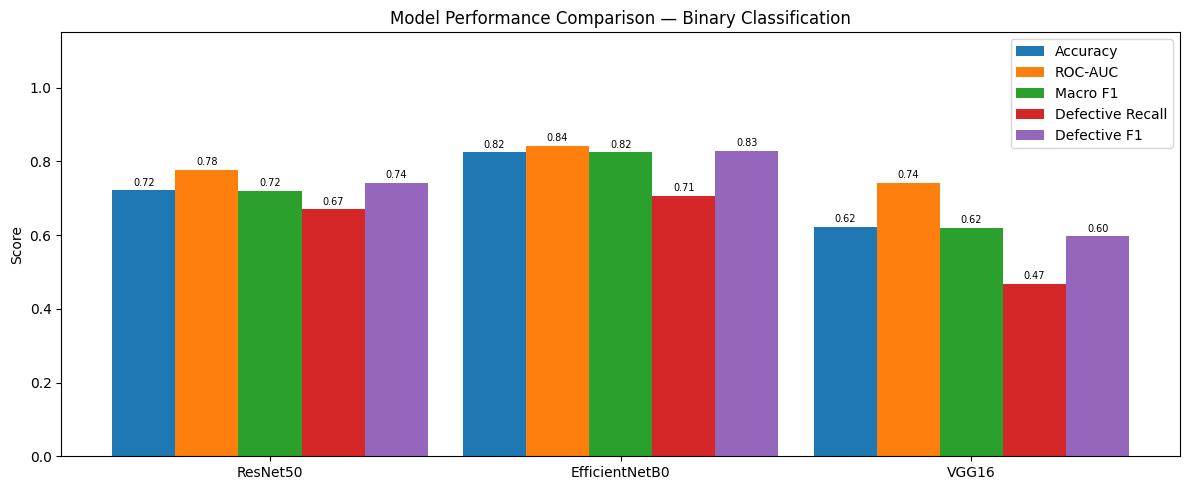

In [22]:
# Summary table
summary_rows = []
for name, data in results.items():
    r = data['report']
    summary_rows.append({
        'Model':             display_names[name],
        'Accuracy':          round(r['accuracy'], 4),
        'ROC-AUC':           round(data['auc'], 4),
        'Good F1':           round(r['Good']['f1-score'], 4),
        'Defective F1':      round(r['Defective']['f1-score'], 4),
        'Macro F1':          round(r['macro avg']['f1-score'], 4),
        'Defective Recall':  round(r['Defective']['recall'], 4),
        'Defective Precision': round(r['Defective']['precision'], 4),
    })

summary_df = pd.DataFrame(summary_rows)
print('\n=== FINAL MODEL COMPARISON ===')
print(summary_df.to_string(index=False))
summary_df.to_csv('model_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 5))
x, w = np.arange(len(summary_df)), 0.18
ax.bar(x - w*2,   summary_df['Accuracy'],         w, label='Accuracy')
ax.bar(x - w,     summary_df['ROC-AUC'],           w, label='ROC-AUC')
ax.bar(x,         summary_df['Macro F1'],          w, label='Macro F1')
ax.bar(x + w,     summary_df['Defective Recall'],  w, label='Defective Recall')
ax.bar(x + w*2,   summary_df['Defective F1'],      w, label='Defective F1')
ax.set_xticks(x)
ax.set_xticklabels(summary_df['Model'])
ax.set_ylim(0, 1.15)
ax.set_title('Model Performance Comparison — Binary Classification')
ax.set_ylabel('Score')
ax.legend(loc='upper right')
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=7)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()